[25.2]


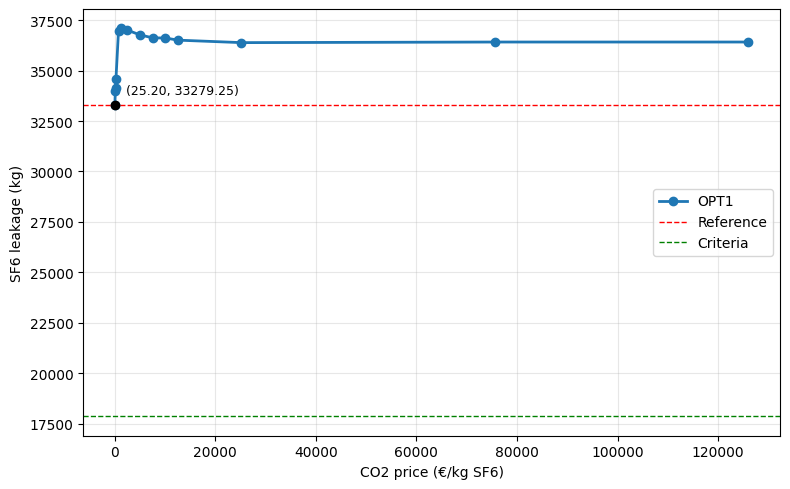

In [ ]:
# CO2 cost analysis for 1CR variant
import matplotlib.pyplot as plt

co2_price = [25.2, 126, 176.4, 252, 504, 756, 1260, 2520, 5040, 7560, 10080, 12600, 25200, 75600, 126000]
sf6_leakage_lineOPT = [33279.25415, 33990.754529627506, 34160.50064733037, 34596.171808183106, 35979.22042592846, 36975.75690372179, 37091.356980061464, 37005.76756793834, 36767.62678541247, 36623.80173626636, 36614.67841088639, 36509.003063568176, 36385.98126356706, 36415.88696135068, 36416.02575456687]

y0 = 33279.25415
y_criteria = 17865.02665 # simulation result
xs = []

plt.figure(figsize=(8, 5))
plt.plot(co2_price, sf6_leakage_lineOPT, marker='o', linewidth=2, label='OPT1')

# add intersection points
for i in range(len(co2_price) - 1):
    y1 = sf6_leakage_lineOPT[i] - y0
    y2 = sf6_leakage_lineOPT[i + 1] - y0

    if y1 == 0:
        xs.append(co2_price[i])
    elif y1 * y2 < 0:
        x1, x2 = co2_price[i], co2_price[i + 1]
        s1, s2 = sf6_leakage_lineOPT[i], sf6_leakage_lineOPT[i + 1]
        x_int = x1 + (y0 - s1) * (x2 - x1) / (s2 - s1)
        xs.append(x_int)

print(xs)

plt.axhline(y=y0, color='red', linestyle='--', linewidth=1, label='Reference')
plt.axhline(y=y_criteria, color='green', linestyle='--', linewidth=1, label='Criteria')

for x in xs:
    plt.scatter(x, y0, color='black', zorder=5)
    plt.annotate(f'({x:.2f}, {y0:.2f})',
                 xy=(x, y0),
                 xytext=(8, 8),
                 textcoords='offset points',
                 fontsize=9,
                 color='black')

plt.xlabel('CO2 price (€/kg SF6)')
plt.ylabel('SF6 leakage (kg)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

[25.2, 1138.6886054026013]


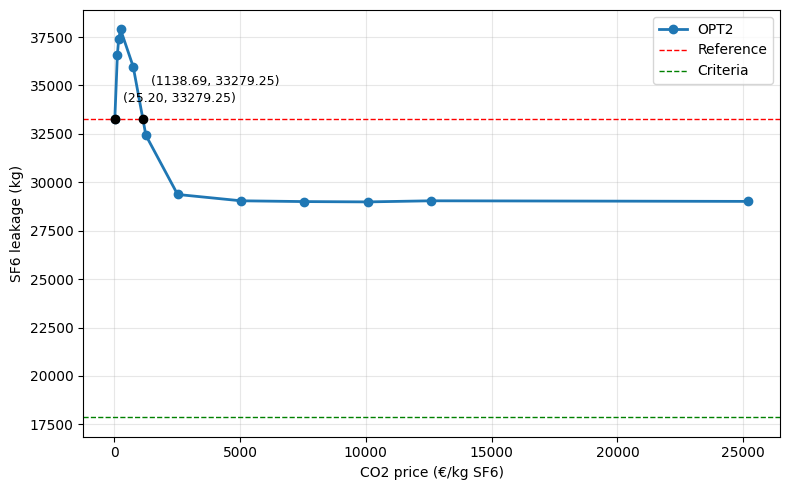

In [23]:
# CO2 cost analysis for mu variant
import matplotlib.pyplot as plt

co2_price = [25.2, 126, 176.4, 252, 756, 1260, 2520, 5040, 7560, 10080, 12600, 25200]
sf6_leakage_lineOPT = [33279.25415, 36569.98587336061, 37378.66118762652, 37896.83263403902, 35969.18264239271, 32426.553097048243, 29372.883175964736, 29045.95622031439, 29005.34824024937, 28989.359054468572, 29045.95622031439, 29015.2671609691]

y0 = 33279.25415
y_criteria = 17865.02665  # simulation result
xs = []

plt.figure(figsize=(8, 5))
plt.plot(co2_price, sf6_leakage_lineOPT, marker='o', linewidth=2, label='OPT2')

# add intersection points
for i in range(len(co2_price) - 1):
    y1 = sf6_leakage_lineOPT[i] - y0
    y2 = sf6_leakage_lineOPT[i + 1] - y0

    if y1 == 0:
        xs.append(co2_price[i])
    elif y1 * y2 < 0:
        x1, x2 = co2_price[i], co2_price[i + 1]
        s1, s2 = sf6_leakage_lineOPT[i], sf6_leakage_lineOPT[i + 1]
        x_int = x1 + (y0 - s1) * (x2 - x1) / (s2 - s1)
        xs.append(x_int)

print(xs)

plt.axhline(y=y0, color='red', linestyle='--', linewidth=1, label='Reference')
plt.axhline(y=y_criteria, color='green', linestyle='--', linewidth=1, label='Criteria')

# 画交点
for x in xs:
    plt.scatter(x, y0, color='black', zorder=5)

# 标注时根据 x 自动决定左右，并垂直错开
for idx, x in enumerate(xs):
    # 根据 x 在图中的相对位置决定左右
    x_mid = (min(co2_price) + max(co2_price)) / 2
    ha = 'left' if x < x_mid else 'right'
    offset_x = 6 if ha == 'left' else -6

    # 垂直方向依次往上挪
    offset_y = 10 + idx * 12

    plt.annotate(
        f'({x:.2f}, {y0:.2f})',
        xy=(x, y0),
        xytext=(offset_x, offset_y),
        textcoords='offset points',
        fontsize=9,
        color='black',
        ha=ha,
        va='bottom'
    )

plt.xlabel('CO2 price (€/kg SF6)')
plt.ylabel('SF6 leakage (kg)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()